# 05 - Predicting no paid purchase in the next 30 days

Positive class: no eligible paid basket in `(cutoff, cutoff+30]`. Population: previously purchasing households active within the previous 180 days. This predicts observed non-purchase, not permanent churn or causal responsiveness to a coupon.

Features contain no IDs, future purchases, labels, future segments or campaign outcomes. Temporal splits include gaps between the last training label and validation, and between validation labels and test. Households may repeat across periods: this evaluates forecasting known customers, not generalisation to unseen customers.

**Step 1: Prepare imports, imports, imports.**

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

plt.ioff()
from IPython.display import display, Markdown

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/retail_customer_360/metrics.py").is_file()
    ),
    None,
)


**Step 2: Prepare config, FIGURES.**

In [2]:
if ROOT is None:
    raise RuntimeError("Open inside retail-customer-360")
sys.path.insert(0, str(ROOT / "src"))
config = json.loads((ROOT / "config/project.json").read_text())
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
BLUE, TEAL, ORANGE = "#245C83", "#208778", "#D77931"


**Step 3: Define the finish helper.**

In [3]:
from IPython.display import Image as NotebookImage


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight", facecolor="white")
    display(NotebookImage(filename=str(FIGURES / name)))
    plt.close(fig)


**Step 4: Load data and inspect the input.**

In [4]:
from retail_customer_360.metrics import load_transactions
from retail_customer_360.customer_analytics import create_baskets, FEATURES, features_at
from retail_customer_360.modeling import train_models, split_cutoffs

con = load_transactions(ROOT)
AS_OF_DAY = con.execute("""SELECT max(day)
FROM raw_transactions""").fetchone()[0]
create_baskets(con, AS_OF_DAY)
cutoffs = split_cutoffs(AS_OF_DAY)


**Step 5: Inspect the intermediate result.**

In [5]:
display(
    pd.DataFrame([
        {"split": k, "cutoff_days": str(v), "last_label_end": max(v) + 30}
        for k, v in cutoffs.items()
    ])
)
display(pd.DataFrame({"features": FEATURES}))


,split,cutoff_days,last_label_end
0,train,"[210, 240, 270, 300, 330, 360, 390, 420]",450
1,validation,"[480, 510]",540
2,test,"[570, 600, 630, 660]",690


,features
0,recency
1,observed_history_days
2,frequency_30
3,frequency_60
4,frequency_90
5,frequency_180
6,monetary_30
7,monetary_180
8,purchase_days_180
9,average_basket_180


## 1. Train baselines and candidate models

Models: constant training prevalence; logistic regression using only recency; scaled multivariate logistic regression; Random Forest with fixed regularisation. Hyperparameters and seed are in source/config. Select once by validation average precision, tie-break by Brier score, then calculate test metrics. AP summarises precision-recall ranking; Brier and calibration inspect probability quality. No test-based parameter tuning or claim of perfect calibration.

**Step 6: Fit and compare the models.**

In [6]:
result = train_models(con, AS_OF_DAY, config)
display(result["manifest"])
display(result["validation_metrics"])
display(result["test_metrics"])
selected = result["manifest"]["selected_model"]
assert max(cutoffs["train"]) + 30 < min(cutoffs["validation"])
assert max(cutoffs["validation"]) + 30 < min(cutoffs["test"])
fig = Figure(figsize=(12, 4.5))
axes = fig.subplots(1, 2)


{'selected_model': 'random_forest',
 'selection_rule': 'Maximum validation average precision; then lower Brier score',
 'features': ['recency',
  'observed_history_days',
  'frequency_30',
  'frequency_60',
  'frequency_90',
  'frequency_180',
  'monetary_30',
  'monetary_180',
  'purchase_days_180',
  'average_basket_180',
  'frequency_trend_30'],
 'cutoffs': {'train': [210, 240, 270, 300, 330, 360, 390, 420],
  'validation': [480, 510],
  'test': [570, 600, 630, 660]},
 'label_horizon_days': 30,
 'evaluation_fit': 'train only',
 'deployment_fit': 'train + validation + test, after frozen evaluation',
 'latest_complete_label_end': 690,
 'positive_class': 'No eligible paid basket in (cutoff, cutoff+30]',
 'population': 'Previously purchasing household with a paid basket in the last 180 days',
 'limitation': 'Repeated households across time; evaluation is forecasting known customers, not unseen-customer generalisation.'}

,model,rows,no_purchase_prevalence,roc_auc,average_precision,brier_score,log_loss,precision_at_10pct,recall_at_10pct,precision_at_05,recall_at_05
0,constant_prior,4798,0.160484,0.500000,0.160484,0.134964,0.441304,0.152083,0.094805,0.000000,0.000000
1,recency_baseline,4798,0.160484,0.807991,0.503863,0.108062,0.361858,0.610417,0.380519,0.692000,0.224675
2,logistic_regression,4798,0.160484,0.875505,0.564859,0.094682,0.302514,0.620833,0.387013,0.663185,0.329870
3,random_forest,4798,0.160484,0.880859,0.578131,0.093282,0.295461,0.641667,0.400000,0.640919,0.398701


,model,rows,no_purchase_prevalence,roc_auc,average_precision,brier_score,log_loss,precision_at_10pct,recall_at_10pct,precision_at_05,recall_at_05
0,constant_prior,9670,0.161944,0.500000,0.161944,0.135911,0.443560,0.168563,0.104087,0.000000,0.000000
1,recency_baseline,9670,0.161944,0.812567,0.488893,0.110282,0.368068,0.596691,0.368455,0.653448,0.242018
2,logistic_regression,9670,0.161944,0.866929,0.530209,0.098492,0.311833,0.599793,0.370370,0.624848,0.327586
3,random_forest,9670,0.161944,0.873106,0.544646,0.097414,0.304548,0.609100,0.376117,0.603159,0.390166


**Step 7: Build the chart.**

In [7]:
for ax, frame, title in [
    (axes[0], result["validation_metrics"], "Validation: model selection"),
    (axes[1], result["test_metrics"], "Frozen test: report only"),
]:
    ax.barh(
        frame.model,
        frame.average_precision,
        color=[TEAL if x == selected else BLUE for x in frame.model],
    )
    ax.axvline(
        frame.no_purchase_prevalence.iloc[0],
        linestyle="--",
        color=ORANGE,
        label="No-purchase prevalence",
    )
    ax.set(xlabel="Average precision", xlim=(0, 1), title=title)
    ax.legend(frameon=False)


**Step 8: Finish and display the chart.**

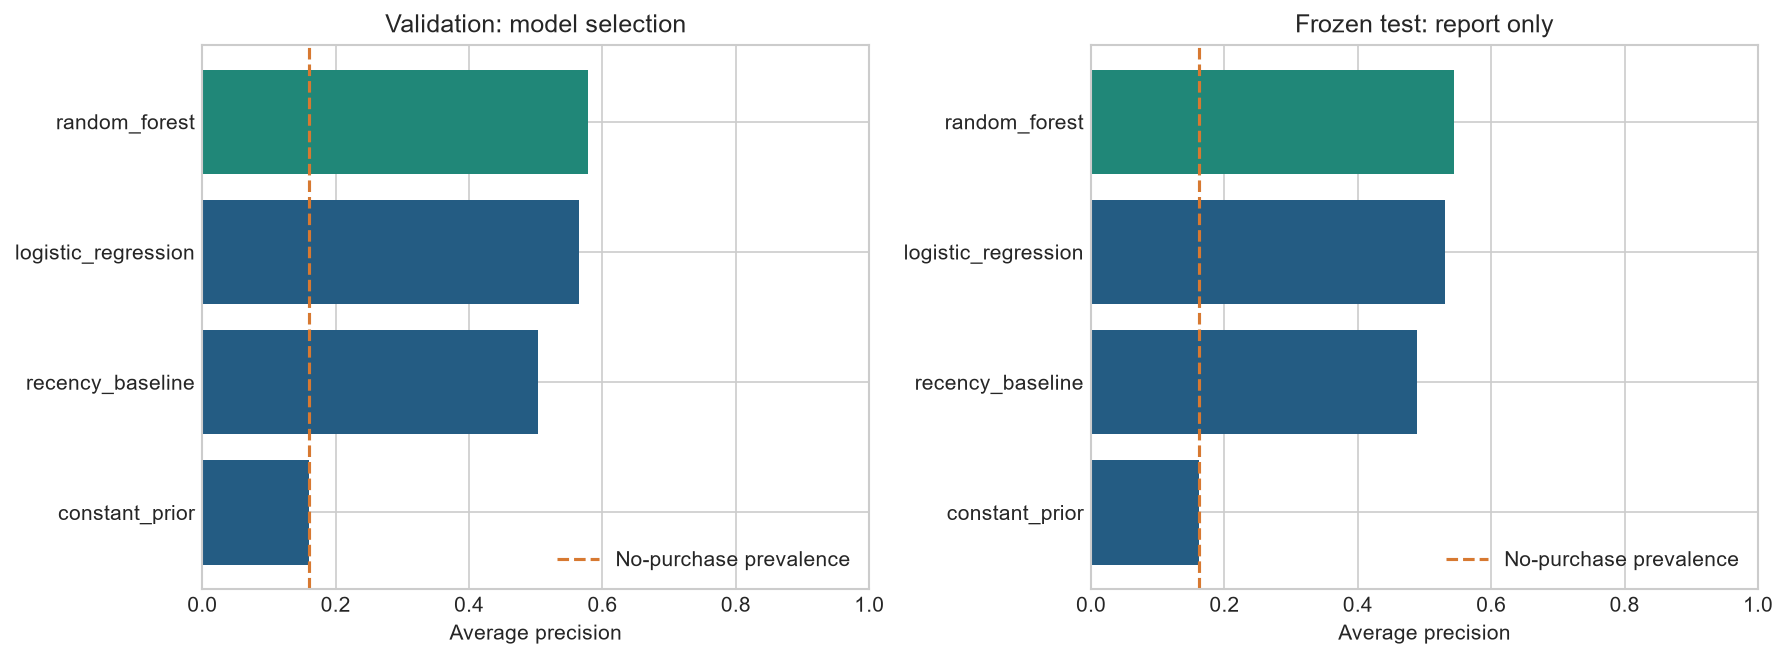

,cutoff_day,rows,no_purchase_prevalence,roc_auc,average_precision,brier_score,log_loss,precision_at_10pct,recall_at_10pct,precision_at_05,recall_at_05
0,570,2419,0.155023,0.873616,0.550394,0.094312,0.297346,0.595041,0.384000,0.567669,0.402667
1,600,2415,0.156522,0.874129,0.538618,0.095881,0.298691,0.586777,0.375661,0.585271,0.399471
2,630,2416,0.164735,0.877353,0.542348,0.098192,0.302884,0.619835,0.376884,0.620968,0.386935
3,660,2420,0.171488,0.868466,0.556692,0.101269,0.319252,0.640496,0.373494,0.643154,0.373494


In [8]:
finish(fig, "05_model_average_precision.png")
display(result["test_by_cutoff"])


## 2. Ranking curves and calibration on the untouched test rows

Test rows include repeated household snapshots. Metrics are descriptive pooled forecasting performance; no independence-based confidence intervals are claimed. The constant baseline has tied scores. Classification at 0.5 is a diagnostic, not the CRM selection rule.

**Step 9: Build the chart.**

In [9]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

pred = result["test_predictions"]
fig = Figure(figsize=(12, 4.5))
axes = fig.subplots(1, 2)


**Step 10: Build the chart.**

In [10]:
for name, frame in pred.groupby("model"):
    fpr, tpr, _ = roc_curve(frame.no_purchase_30d, frame.risk_probability)
    precision, recall, _ = precision_recall_curve(
        frame.no_purchase_30d, frame.risk_probability
    )
    axes[0].plot(fpr, tpr, label=name)
    if name == "constant_prior":
        axes[1].axhline(
            frame.no_purchase_30d.mean(),
            color="grey",
            linestyle="--",
            label="Constant-prior prevalence reference",
        )
    else:
        axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--")


**Step 11: Finish and display the chart.**

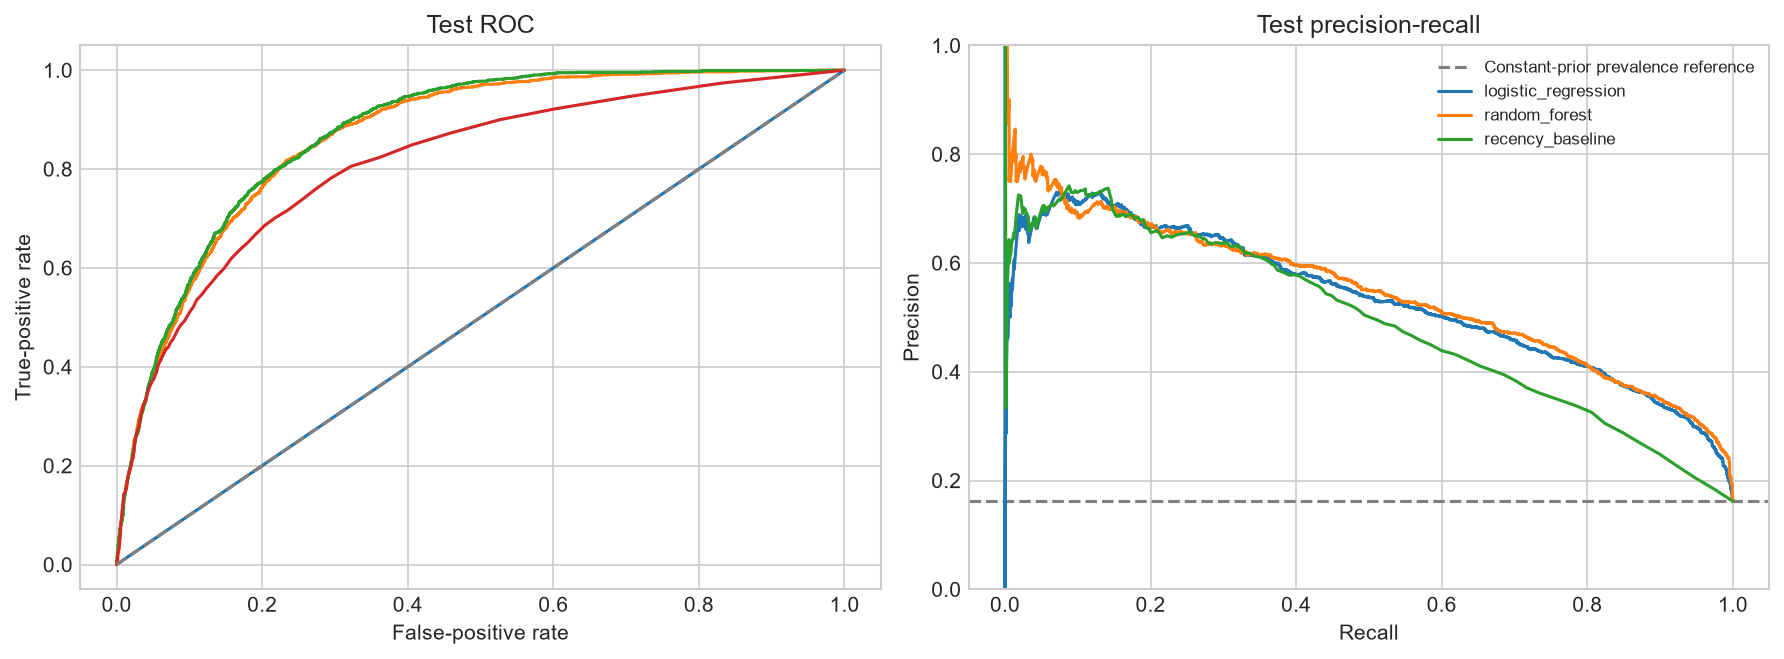

In [11]:
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate", title="Test ROC")
axes[1].set(
    xlabel="Recall", ylabel="Precision", title="Test precision-recall", ylim=(0, 1)
)
axes[1].legend(fontsize=8, frameon=False)
finish(fig, "05_test_ranking_curves.png")
chosen = pred.loc[pred.model == selected].copy()
chosen["bin"] = np.minimum((chosen.risk_probability * 10).astype(int), 9)


**Step 12: Build the chart.**

In [12]:
calibration = (
    chosen.groupby("bin")
    .agg(
        rows=("no_purchase_30d", "size"),
        mean_prediction=("risk_probability", "mean"),
        observed_rate=("no_purchase_30d", "mean"),
    )
    .reset_index()
)
display(calibration)
fig = Figure(figsize=(6, 5))
ax = fig.subplots()
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Ideal calibration")


,bin,rows,mean_prediction,observed_rate
0,0,5479,0.021623,0.025005
1,1,1193,0.144755,0.152557
2,2,668,0.249292,0.224551
3,3,651,0.350619,0.327189
4,4,666,0.450776,0.409910
5,5,438,0.541783,0.534247
6,6,415,0.649012,0.624096
7,7,120,0.731897,0.725000
8,8,40,0.828259,0.775000


**Step 13: Finish and display the chart.**

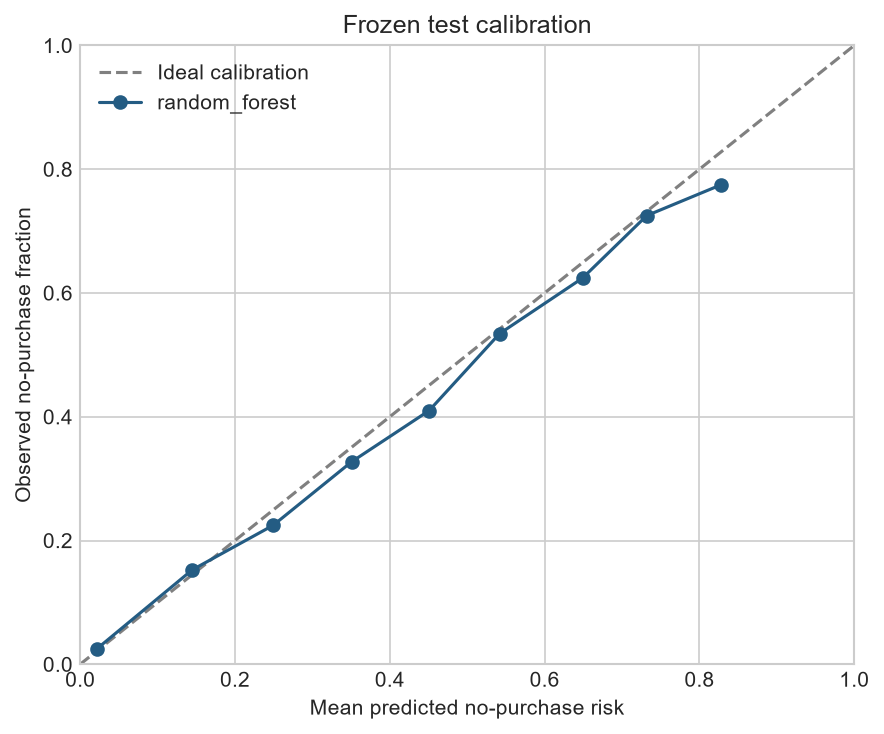

In [13]:
ax.plot(
    calibration.mean_prediction,
    calibration.observed_rate,
    marker="o",
    color=BLUE,
    label=selected,
)
ax.set(
    xlabel="Mean predicted no-purchase risk",
    ylabel="Observed no-purchase fraction",
    title="Frozen test calibration",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(frameon=False)
finish(fig, "05_test_calibration.png")


**Step 14: Inspect the intermediate result.**

In [14]:
display(
    pd.DataFrame(
        confusion_matrix(chosen.no_purchase_30d, chosen.risk_probability >= 0.5),
        index=["Actual purchase", "Actual no purchase"],
        columns=["Predicted purchase", "Predicted no purchase"],
    )
)


,Predicted purchase,Predicted no purchase
Actual purchase,7702,402
Actual no purchase,955,611


## 3. Latest scoring without invented future labels

After evaluation is frozen, refit the selected architecture on all completed labelled snapshots for deployment. This refit does not replace the test metrics above. Score the latest cutoff only for the same active-180-day population. The next 30 days beyond the dataset are unobserved and must remain unlabelled. Predictive feature importance is association, not a reason why customers leave.

**Step 15: Check the calculation.**

In [15]:
latest = features_at(con, AS_OF_DAY)
latest = latest.loc[latest.recency < 180].copy()
latest["risk_probability"] = result["model"].predict_proba(latest[FEATURES])[:, 1]
display(
    latest[
        ["household_key", "cutoff_day", "recency", "frequency_180", "risk_probability"]
    ].head(10)
)
assert "no_purchase_30d" not in latest
print("Latest scored households:", len(latest))
model = result["evaluation_model"]


,household_key,cutoff_day,recency,frequency_180,risk_probability
0,1,711,5,28,0.018735
1,2,711,43,9,0.353984
2,3,711,8,6,0.391275
3,4,711,84,4,0.560315
4,5,711,8,8,0.329064
5,6,711,4,68,0.004364
6,7,711,2,26,0.013367
7,8,711,5,34,0.019227
8,9,711,22,8,0.250182
9,10,711,26,2,0.503137


Latest scored households: 2430


In [16]:
display(latest.head())


,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30,risk_probability
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4,0.018735
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1,0.353984
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0,0.391275
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0,0.560315
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2,0.329064


In [17]:
display(latest.head())


,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30,risk_probability
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4,0.018735
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1,0.353984
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0,0.391275
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0,0.560315
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2,0.329064


**Step 16: Finish and display the chart.**

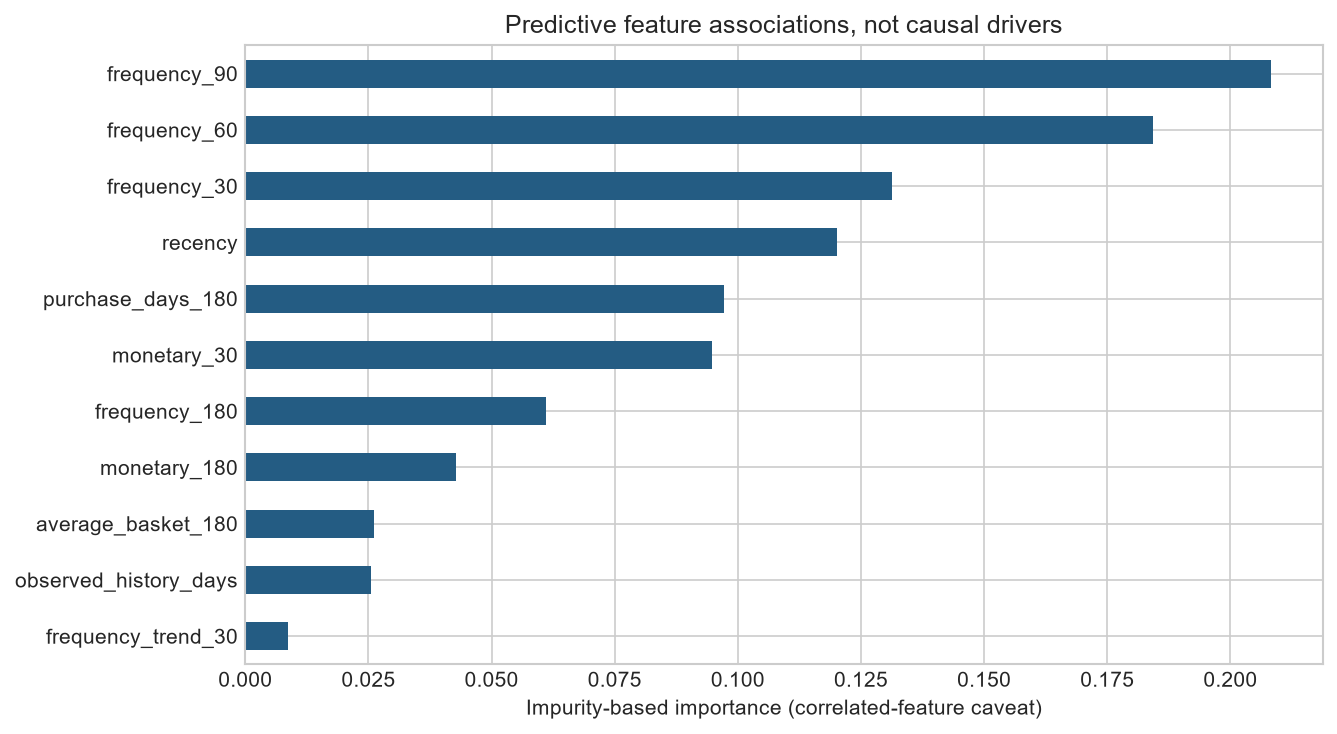

In [18]:
if hasattr(model, "feature_importances_"):
    importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
    fig = Figure(figsize=(9, 5))
    ax = fig.subplots()
    importance.plot.barh(ax=ax, color=BLUE)
    ax.set(
        xlabel="Impurity-based importance (correlated-feature caveat)",
        title="Predictive feature associations, not causal drivers",
    )
    finish(fig, "05_predictive_feature_importance.png")
con.close()


## Practical limits

No external retailer validation, probability recalibration, subgroup fairness study or causal uplift estimation is claimed. Compare AP and Brier against the recency baseline, not only the constant baseline. Persisted pipeline artefacts include selected-model metadata, complete split cutoffs, test predictions, deployment model and source hashes. Load only model files generated locally by this project.